In [65]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/faceshape-processed/dataset/test/Oval/Oval(32).jpg
/kaggle/input/faceshape-processed/dataset/test/Oval/Oval(123).jpg
/kaggle/input/faceshape-processed/dataset/test/Oval/Oval(194).jpg
/kaggle/input/faceshape-processed/dataset/test/Oval/Oval(125).jpg
/kaggle/input/faceshape-processed/dataset/test/Oval/Oval(76).jpg
/kaggle/input/faceshape-processed/dataset/test/Oval/Oval(122).jpg
/kaggle/input/faceshape-processed/dataset/test/Oval/Oval(119).jpg
/kaggle/input/faceshape-processed/dataset/test/Oval/Oval(190).jpg
/kaggle/input/faceshape-processed/dataset/test/Oval/Oval(30).jpg
/kaggle/input/faceshape-processed/dataset/test/Oval/Oval(121).jpg
/kaggle/input/faceshape-processed/dataset/test/Oval/Oval(72).jpg
/kaggle/input/faceshape-processed/dataset/test/Oval/Oval(105).jpg
/kaggle/input/faceshape-processed/dataset/test/Oval/Oval(178).jpg
/kaggle/input/faceshape-processed/dataset/test/Oval/Oval(40).jpg
/kaggle/input/faceshape-processed/dataset/test/Oval/Oval(29).jpg
/kaggle/input/fa

In [66]:
import tensorflow as tf

In [67]:
import tensorflow as tf

train_dir = "/kaggle/input/faceshape-processed/dataset/train"
test_dir = "/kaggle/input/faceshape-processed/dataset/test"

# Training dataset
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(32, 32),   # resize to 28x28
    color_mode="grayscale",  # convert to grayscale
    batch_size=32,
    shuffle=True
)

# Testing dataset
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(32, 32),
    color_mode="grayscale",
    batch_size=32,
    shuffle=False
)


Found 3981 files belonging to 5 classes.
Found 998 files belonging to 5 classes.


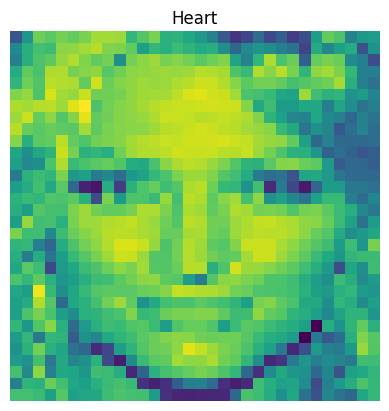

In [68]:
import matplotlib.pyplot as plt

class_names = train_ds.class_names

for images, labels in test_ds.take(1):
    plt.imshow(images[0].numpy().astype("uint8"))   # show first image
    plt.title(class_names[labels[0]])
    plt.axis("off")
    plt.show()


In [69]:
import numpy as np

# Training data
x_train, y_train = [], []
for images, labels in train_ds:
    x_train.append(images.numpy())
    y_train.append(labels.numpy())
x_train = np.concatenate(x_train)
y_train = np.concatenate(y_train)

# Testing data
x_test, y_test = [], []
for images, labels in test_ds:
    x_test.append(images.numpy())
    y_test.append(labels.numpy())
x_test = np.concatenate(x_test)
y_test = np.concatenate(y_test)




In [70]:
x_train[0]

array([[[ 16.117188 ],
        [ 54.04004  ],
        [ 18.973633 ],
        ...,
        [230.2959   ],
        [236.1875   ],
        [242.53125  ]],

       [[ 53.668945 ],
        [  8.458984 ],
        [ 27.46875  ],
        ...,
        [191.80078  ],
        [237.59375  ],
        [245.10254  ]],

       [[ 19.014648 ],
        [ 23.65625  ],
        [ 13.854492 ],
        ...,
        [166.29492  ],
        [216.29395  ],
        [245.4541   ]],

       ...,

       [[ 48.966797 ],
        [  5.024414 ],
        [  4.958008 ],
        ...,
        [219.55273  ],
        [234.18164  ],
        [193.35645  ]],

       [[ 60.50586  ],
        [ 40.4209   ],
        [  7.8251953],
        ...,
        [225.33105  ],
        [237.72363  ],
        [197.92383  ]],

       [[ 49.65918  ],
        [ 63.94629  ],
        [ 13.154297 ],
        ...,
        [212.0625   ],
        [238.78125  ],
        [232.55664  ]]], dtype=float32)

In [71]:
x_train=x_train/255.00
x_test=x_test/255.00

In [72]:
x_train.shape

(3981, 32, 32, 1)

In [73]:
x_test.shape

(998, 32, 32, 1)

Building the model:

In [74]:
from tensorflow.keras.layers import Dense,Conv2D,AveragePooling2D,Flatten,Dropout
from tensorflow.keras.models import Sequential

In [75]:
input_shape=(32,32,1)

model=Sequential()
model.add(Conv2D(filters=6, kernel_size=(5,5), strides=(1,1), 
                 activation='tanh', input_shape=input_shape))

# S2 - Average Pooling
model.add(AveragePooling2D(pool_size=(2,2), strides=(2,2)))

# C3 - Conv
model.add(Conv2D(filters=16, kernel_size=(5,5), strides=(1,1), activation='tanh'))

# S4 - Average Pooling
model.add(AveragePooling2D(pool_size=(2,2), strides=(2,2)))

# Flatten before Dense
model.add(Flatten())

# C5 - Dense
model.add(Dense(units=120, activation='tanh'))

# F6 - Dense
model.add(Dense(units=84, activation='tanh'))


# Output layer (5 classes in your dataset)
model.add(Dense(units=5, activation='softmax'))


In [76]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [77]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)



In [78]:
history=model.fit(train_ds,epochs=100,validation_data=test_ds,batch_size=32,callbacks=[early_stop])

Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.2691 - loss: 1.5889 - val_accuracy: 0.3878 - val_loss: 1.4131
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.4349 - loss: 1.3465 - val_accuracy: 0.4238 - val_loss: 1.3416
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.4934 - loss: 1.2501 - val_accuracy: 0.5080 - val_loss: 1.2203
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.5203 - loss: 1.1731 - val_accuracy: 0.5070 - val_loss: 1.2167
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.5520 - loss: 1.1261 - val_accuracy: 0.5381 - val_loss: 1.1582
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.5512 - loss: 1.1160 - val_accuracy: 0.5401 - val_loss: 1.1520
Epoch 7/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.5848 - loss: 1.0804 - val_accuracy: 0.5681 - val_loss: 1.1014
Epoch 8/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.5808 - loss: 1.0624 - 

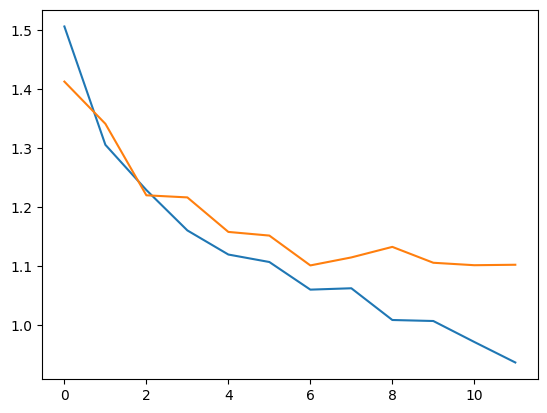

In [79]:
import matplotlib.pyplot as plt
plt.plot(history.history['loss'],label="Training loss")
plt.plot(history.history['val_loss'],label="Value loss")
plt.show()

In [80]:
test_loss, test_acc = model.evaluate(test_ds)
print("Test Accuracy:", test_acc)


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5933 - loss: 1.0834
Test Accuracy: 0.5681362748146057


In [81]:
import numpy as np

# Take one batch from test_ds
for images, labels in test_ds.take(1):
    preds = model.predict(images)
    predicted_classes = np.argmax(preds, axis=1)
    true_classes = labels.numpy()
    print("Predicted:", predicted_classes[:5])
    print("True:", true_classes[:5])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
Predicted: [1 1 0 0 0]
True: [0 0 0 0 0]
